# <span style="color:darkblue"> Lecture 15b: Time Series Cross-Validation </span>


# <span style="color:darkblue"> I. Setup Working Environment </span>


<font size = "5">

Import data from Introduction to Statistical Learning

In [11]:
from ISLP import load_data
from ISLP.models import summarize

<font size = "5">

Import standard packages

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm


<font size = "5">

Import SK-learn packages


In [13]:
# Import SK-Learn library for machine learning functions
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_validate
from sklearn import preprocessing

# <span style="color:darkblue"> II. Data </span>


<font size = "5">

Import data from Introduction to Statistical Learning

- This is time series data
- It is sorted from earlier time periods to later time periods

In [14]:
Smarket = load_data('Smarket')
Smarket

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today,Direction
0,2001,0.381,-0.192,-2.624,-1.055,5.010,1.19130,0.959,Up
1,2001,0.959,0.381,-0.192,-2.624,-1.055,1.29650,1.032,Up
2,2001,1.032,0.959,0.381,-0.192,-2.624,1.41120,-0.623,Down
3,2001,-0.623,1.032,0.959,0.381,-0.192,1.27600,0.614,Up
4,2001,0.614,-0.623,1.032,0.959,0.381,1.20570,0.213,Up
...,...,...,...,...,...,...,...,...,...
1245,2005,0.422,0.252,-0.024,-0.584,-0.285,1.88850,0.043,Up
1246,2005,0.043,0.422,0.252,-0.024,-0.584,1.28581,-0.955,Down
1247,2005,-0.955,0.043,0.422,0.252,-0.024,1.54047,0.130,Up
1248,2005,0.130,-0.955,0.043,0.422,0.252,1.42236,-0.298,Down


<Axes: >

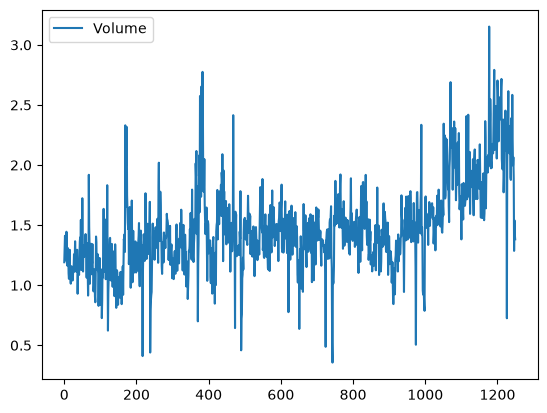

In [15]:
Smarket.plot(y='Volume')

# <span style="color:darkblue"> III. Expanding window cross-validation </span>

<font size = "5">

Try it yourself!

In this exercise you will code up your own time series <br>
cross-validation algorith:


<font size = "3">

PART I:


- Create an index for observation number
- Split the data in half. However, do not do it at random, <br>
instead set the training data to be the first set of observations
- Train an Decision Tree model on the first half.
- Test how well it does on the next observations in terms of MSE.

PART II:
- Now construct a training dataset that includes half + one more observation
- Train the Decision Tree and check its performance in terms of MSE.

PART III:
- Create a loop that repeats this process 10 more times, adding <br>
one more observation to the training set each time.

This is expanding window cross-validation!







In [16]:
# PART I
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

# Create an index for observation number (data is already sorted by time)
Smarket["obs_num"] = np.arange(len(Smarket))

# Features and target: predict today's return from past returns and volume
features = ["Lag1", "Lag2", "Lag3", "Lag4", "Lag5", "Volume"]
target = "Today"

# Split in half by time, not at random: first half trains, second half tests
half = len(Smarket) // 2
train = Smarket[Smarket["obs_num"] < half]
test = Smarket[Smarket["obs_num"] >= half]

# Train a Decision Tree on the first half
tree = DecisionTreeRegressor(max_depth=3, random_state=0)
tree.fit(train[features], train[target])

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``m

In [17]:
# Test on the later observations
pred = tree.predict(test[features])
mse = mean_squared_error(test[target], pred)

print(f"Training obs: {len(train)} (obs 0 to {half - 1})")
print(f"Test obs:     {len(test)} (obs {half} to {len(Smarket) - 1})")
print(f"Test MSE:     {mse:.4f}")

Training obs: 625 (obs 0 to 624)
Test obs:     625 (obs 625 to 1249)
Test MSE:     0.4937


In [18]:
# PART 2
# Training set: first half plus one more observation
cutoff = half + 1
train2 = Smarket[Smarket["obs_num"] < cutoff]
test2 = Smarket[Smarket["obs_num"] >= cutoff]

# Train the Decision Tree on the expanded training set
tree2 = DecisionTreeRegressor(max_depth=3, random_state=0)
tree2.fit(train2[features], train2[target])

# Check performance on the remaining later observations
pred2 = tree2.predict(test2[features])
mse2 = mean_squared_error(test2[target], pred2)

print(f"Training obs: {len(train2)} (obs 0 to {cutoff - 1})")
print(f"Test obs:     {len(test2)} (obs {cutoff} to {len(Smarket) - 1})")
print(f"Test MSE:     {mse2:.4f}")

Training obs: 626 (obs 0 to 625)
Test obs:     624 (obs 626 to 1249)
Test MSE:     0.4923


In [19]:
# PART 3
# Repeat 10 more times, adding one more observation to the training set each time
results = []

for cutoff in range(half + 2, half + 12):
    train_k = Smarket[Smarket["obs_num"] < cutoff]
    test_k = Smarket[Smarket["obs_num"] >= cutoff]

    tree_k = DecisionTreeRegressor(max_depth=3, random_state=0)
    tree_k.fit(train_k[features], train_k[target])

    pred_k = tree_k.predict(test_k[features])
    mse_k = mean_squared_error(test_k[target], pred_k)

    results.append({"train_size": len(train_k), "test_size": len(test_k), "mse": mse_k})

results = pd.DataFrame(results)
print(results)
print(f"\nAverage MSE across the 10 windows: {results['mse'].mean():.4f}")

   train_size  test_size       mse
0         627        623  0.492212
1         628        622  0.492989
2         629        621  0.493495
3         630        620  0.492556
4         631        619  0.490302
5         632        618  0.488535
6         633        617  0.487207
7         634        616  0.487922
8         635        615  0.488312
9         636        614  0.483038

Average MSE across the 10 windows: 0.4897
